Q11: Data Visualization using matplotlib

Analyzing air quality trends in a city.

Use City_Air_Quality.csv from the same folder. This is the existing generated practice dataset, not real observations.

PM2.5 groups divide this dataset into three relative levels; they are not official health classifications.

In [1]:
import pandas as pd
import matplotlib.pyplot as plt

df = pd.read_csv("City_Air_Quality.csv")
df["Date"] = pd.to_datetime(df["Date"])

print(df.head())
df.info()
print("Missing Values:")
print(df.isnull().sum())
print("\nSummary:")
print(df[["PM2.5", "PM10", "CO", "AQI"]].describe())

        Date  PM2.5  PM10    CO  AQI
0 2025-01-01   42.1  76.3  1.25  120
1 2025-01-02   46.3  82.3  1.25  121
2 2025-01-03   32.1  71.7  0.99  101
3 2025-01-04   37.9  58.5  1.02  111
4 2025-01-05   41.5  53.5  1.03  119
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 150 entries, 0 to 149
Data columns (total 5 columns):
 #   Column  Non-Null Count  Dtype         
---  ------  --------------  -----         
 0   Date    150 non-null    datetime64[ns]
 1   PM2.5   150 non-null    float64       
 2   PM10    150 non-null    float64       
 3   CO      150 non-null    float64       
 4   AQI     150 non-null    int64         
dtypes: datetime64[ns](1), float64(3), int64(1)
memory usage: 6.0 KB
Missing Values:
Date     0
PM2.5    0
PM10     0
CO       0
AQI      0
dtype: int64

Summary:
            PM2.5        PM10          CO         AQI
count  150.000000  150.000000  150.000000  150.000000
mean    37.976667   65.491333    1.019067  104.006667
std     11.224927   21.524189    0.188100

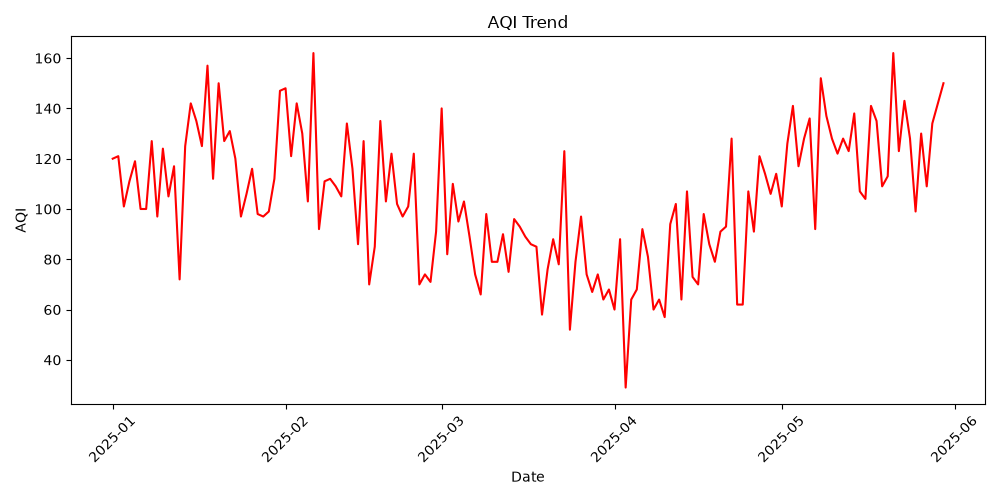

In [2]:
# AQI trend
plt.figure(figsize=(10, 5))
plt.plot(df["Date"], df["AQI"], color="red")
plt.title("AQI Trend")
plt.xlabel("Date")
plt.ylabel("AQI")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

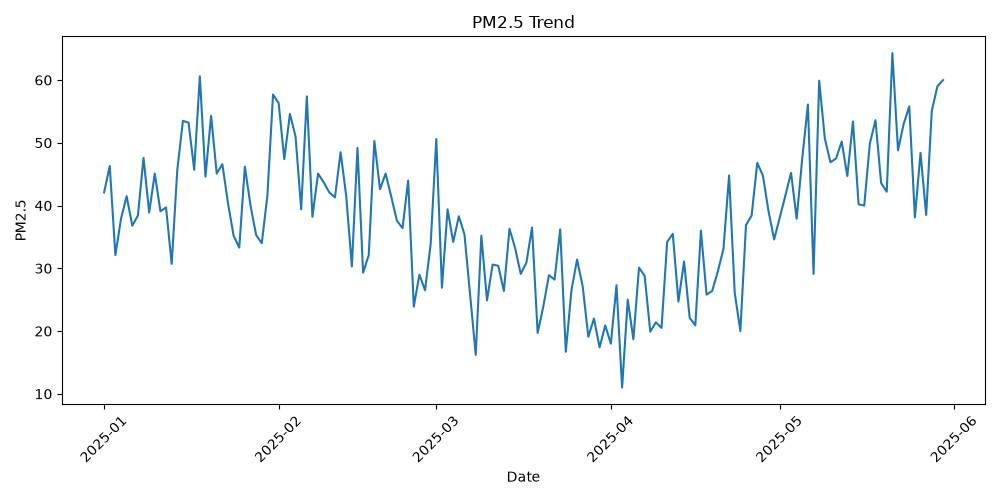

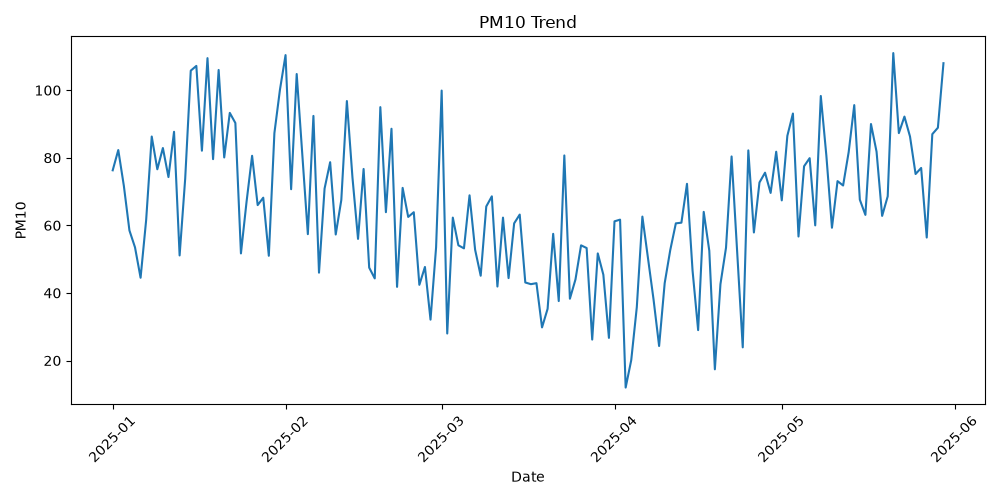

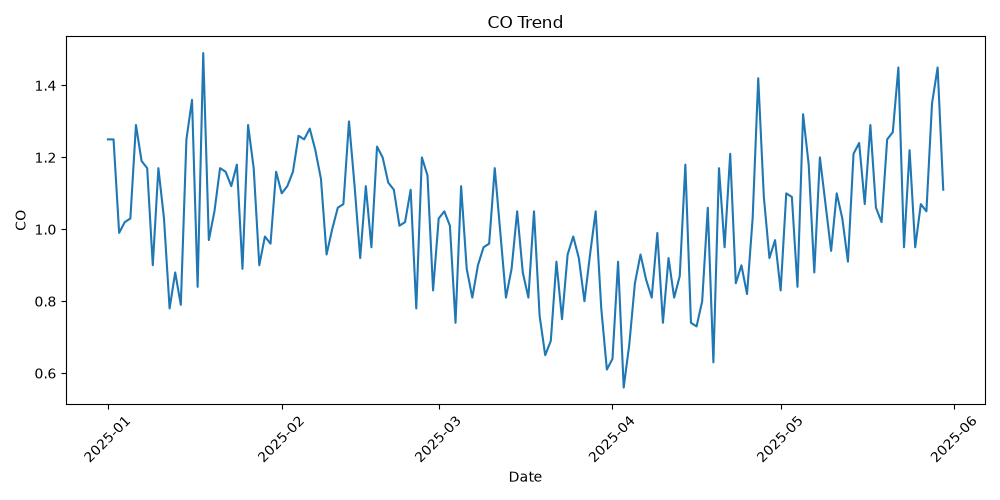

In [3]:
# Separate pollutant trends
for col in ["PM2.5", "PM10", "CO"]:
    plt.figure(figsize=(10, 5))
    plt.plot(df["Date"], df[col])
    plt.title(col + " Trend")
    plt.xlabel("Date")
    plt.ylabel(col)
    plt.xticks(rotation=45)
    plt.tight_layout()
    plt.show()

Month
2025-01    116.451613
2025-02    108.607143
2025-03     84.741935
2025-04     84.166667
2025-05    126.600000
Name: AQI, dtype: float64


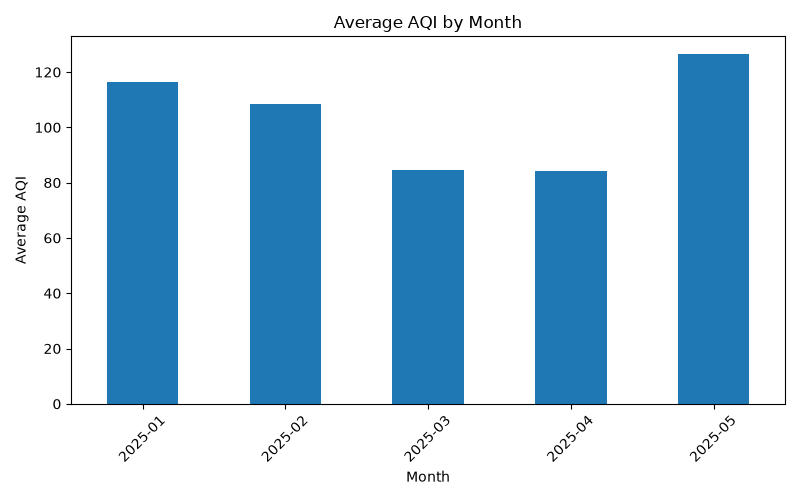

In [4]:
# Average AQI by month
df["Month"] = df["Date"].dt.to_period("M").astype(str)
monthly = df.groupby("Month")["AQI"].mean()
print(monthly)

monthly.plot(kind="bar", figsize=(8, 5))
plt.title("Average AQI by Month")
plt.xlabel("Month")
plt.ylabel("Average AQI")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

              count    mean
PM25Group                  
Lower third      50   75.32
Middle third     50  104.12
Upper third      50  132.58


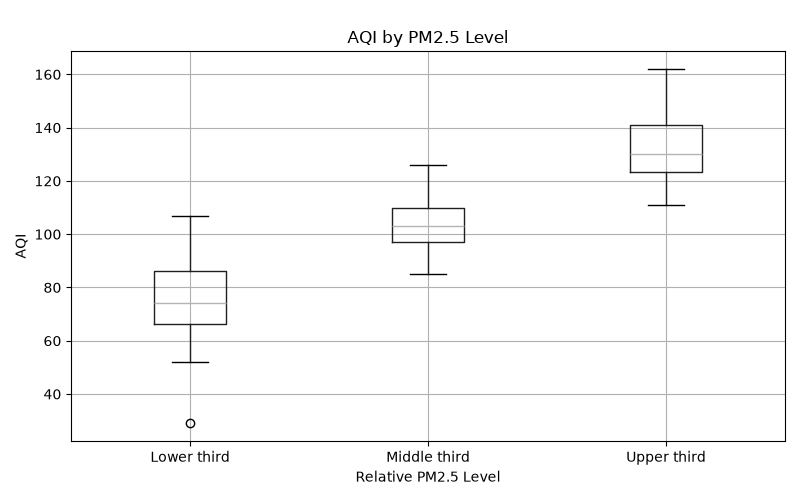

In [5]:
# AQI distribution by relative PM2.5 level
df["PM25Group"] = pd.qcut(df["PM2.5"], q=3, labels=["Lower third", "Middle third", "Upper third"])
print(df.groupby("PM25Group", observed=True)["AQI"].agg(["count", "mean"]))
df.boxplot(column="AQI", by="PM25Group", figsize=(8, 5))
plt.title("AQI by PM2.5 Level")
plt.suptitle("")
plt.xlabel("Relative PM2.5 Level")
plt.ylabel("AQI")
plt.tight_layout()
plt.show()

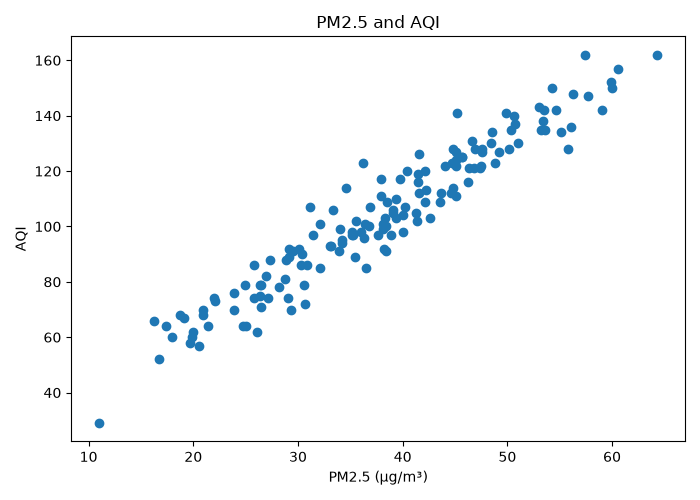

In [6]:
# Relationship between PM2.5 and AQI
plt.figure(figsize=(7, 5))
plt.scatter(df["PM2.5"], df["AQI"])
plt.title("PM2.5 and AQI")
plt.xlabel("PM2.5 (µg/m³)")
plt.ylabel("AQI")
plt.tight_layout()
plt.show()